# Risk Prediction Overview

## Phase 0: Directory location and Modules linked

In [1]:
import sys
from pathlib import Path

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

In [2]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model,
    graph_edge_oversample, 
    evaluate_with_kfold,
    generate_threat_report
)

from core.kg_sna_layer.graph_builder import(
    AsyncKnowledgeGraphManager,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!


In [3]:
import torch
import random
import numpy as np

# Lock the random seed for 100% reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

## Phase 1: Fetching data

In [4]:
from core.config import graph_base
kg_manager = AsyncKnowledgeGraphManager(graph_base.URL, graph_base.USER, graph_base.PASS)
print("Fetching graph data from Neo4j... Done.")

Fetching graph data from Neo4j... Done.


<>:94: SyntaxWarning: invalid escape sequence '\g'
<>:94: SyntaxWarning: invalid escape sequence '\g'
C:\Users\dhara\AppData\Local\Temp\ipykernel_8456\2279771088.py:94: SyntaxWarning: invalid escape sequence '\g'
  plt.text(0, -0.3, f"Threshold $\geq$ 4.0 isolates\ntop {threat_pct:.1f}% as targets",


🔍 Fetching LLM Taxonomy mappings from Neo4j...

✅ Cleaned Data ready for plotting:
   Severity  Frequency           Taxonomy Category
1       1.0        345  Level 1: NEUTRAL/EMOTIONAL
2       2.0        286    Level 2: VIOLATED_SCALED
3       3.0       1402               Level 3: HATE
4       4.0        198             Level 4: THREAT


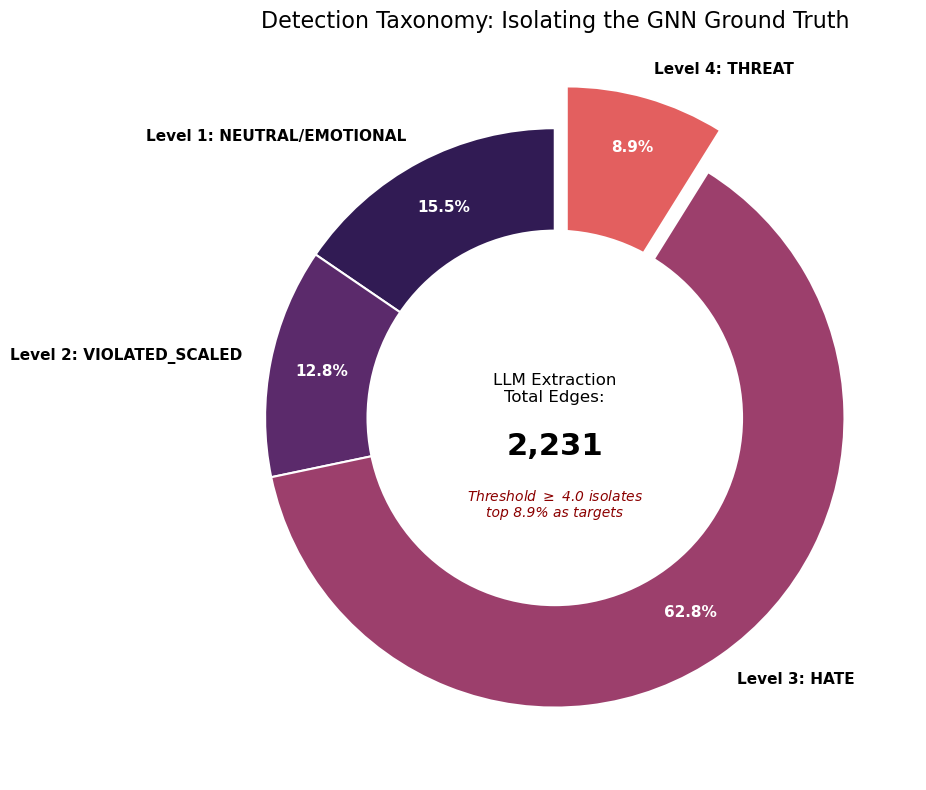

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from neo4j import GraphDatabase
from datetime import datetime

def plot_taxonomy_distribution(uri, user, password):
    print("🔍 Fetching LLM Taxonomy mappings from Neo4j...")
    driver = GraphDatabase.driver(uri, auth=(user, password))
    
    # Query to count how many edges have each risk_weight (Severity)
    query = """
    MATCH ()-[r]->()
    WHERE type(r) <> 'SNA_TIE_STRENGTH' AND r.risk_weight IS NOT NULL
    RETURN r.risk_weight AS severity, count(r) AS frequency
    """
    
    with driver.session() as session:
        result = session.run(query)
        data = [{"Severity": row["severity"], "Frequency": row["frequency"]} for row in result]
        
    driver.close()
    
    if not data:
        print("No taxonomy weights found! Check your database.")
        return
    
    df = pd.DataFrame(data)
    
    # ==========================================
    # THE FIX: Data Cleaning & Grouping
    # ==========================================
    # 1. Force the column to numeric (handles strings)
    df['Severity'] = pd.to_numeric(df['Severity'], errors='coerce')
    
    # 2. Round to the nearest whole number (handles 4.00001)
    df['Severity'] = df['Severity'].round(0)
    
    # 3. Group them up just in case the rounding created duplicates
    df = df.groupby('Severity')['Frequency'].sum().reset_index()
    
    # Now map the severity integers back to your Taxonomy names
    severity_to_name = {
        1.0: "Level 1: NEUTRAL/EMOTIONAL",
        2.0: "Level 2: VIOLATED_SCALED",
        3.0: "Level 3: HATE",
        4.0: "Level 4: THREAT",
        5.0: "Level 5: EXTREMIST/RADICALISM"
    }
    df['Taxonomy Category'] = df['Severity'].map(severity_to_name)
    
    # Drop any weird outliers that didn't fit 1 through 5
    df = df.dropna(subset=['Taxonomy Category'])
    
    print("\n✅ Cleaned Data ready for plotting:")
    print(df)
    
    plt.figure(figsize=(10, 8))
    
    # Extract the cleaned data for the pie chart
    labels = df['Taxonomy Category'].tolist()
    sizes = df['Frequency'].tolist()
    
    # Create a custom color palette (Dark purples for noise, bright red for threats)
    colors = ['#311b54', '#5b2a6b', '#9c3f6c', '#e35f5f', '#fca15d']
    
    # "Explode" (pull away) the Level 4 and Level 5 slices to show the threshold cutoff
    # We dynamically create the explode tuple based on the severity level
    explode = [0.15 if sev >= 4.0 else 0.0 for sev in df['Severity']]
    
    # Plot the Donut Chart
    wedges, texts, autotexts = plt.pie(
        sizes, explode=explode, labels=labels, colors=colors[:len(labels)], 
        autopct='%1.1f%%', startangle=90, pctdistance=0.82,
        textprops={'fontsize': 11, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5, 'antialiased': True}
    )
    
    for autotext in autotexts:
        autotext.set_color('white')
    
    # Draw the white circle in the middle to make it a donut
    centre_circle = plt.Circle((0,0), 0.65, fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(centre_circle)
    
    # Add a central text annotation explaining the methodology
    total_edges = sum(sizes)
    threat_edges = df[df['Severity'] >= 4.0]['Frequency'].sum()
    threat_pct = (threat_edges / total_edges) * 100
    
    plt.text(0, 0.1, "LLM Extraction\nTotal Edges:", ha='center', va='center', fontsize=12)
    plt.text(0, -0.1, f"{total_edges:,}", ha='center', va='center', fontsize=22, fontweight='bold')
    plt.text(0, -0.3, f"Threshold $\geq$ 4.0 isolates\ntop {threat_pct:.1f}% as targets", 
             ha='center', va='center', fontsize=10, color='darkred', fontstyle='italic')
    
    plt.title("Detection Taxonomy: Isolating the GNN Ground Truth", fontsize=16, pad=20)
    
    plt.tight_layout()
    timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.savefig(f"{timestamp_dist}_taxonomy_exploded_donut.png", dpi=300, bbox_inches='tight')
    plt.show()

# Run the function
plot_taxonomy_distribution(graph_base.URL, graph_base.USER, graph_base.PASS)

In case of SNA metrics already loaded, it can be cleaned to show the process from the beggining.

In [7]:
wipe_sna_metrics(graph_base.URL, graph_base.USER, graph_base.PASS)
baseline_data, enriched_data, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data.num_nodes} nodes and {baseline_data.num_edges} edges before SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data.y.sum().item())}")

✅ Deleted SNA_TIE_STRENGTH edges (including Jaccard, CN, and Adamic-Adar).
✅ Removed structural metrics (betweenness, eigenvector, etc.) from nodes.
🧹 Graph successfully reset to its pure semantic state!


Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `common_neighbors` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=8, column=21, offset=271>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 271, 'line': 8, 'column': 21}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        MATCH (a:Inmate)-[r]->(b:Inmate) \n        WHERE type(r) <> 'SNA_TIE_STRENGTH'\n        OPTIONAL MATCH (a)-[meta:SNA_TIE_STRENGTH]->(b)\n        RETURN a.name AS source, \n               b.name AS target, \n               r.risk_weight AS weight,\n               meta.common_neighbors AS cn,\n 

Successfully loaded 52 nodes and 184 edges before SNA calculations.
Total High-Risk Edges (Class 1): 19


Now, the SNA metrics can be added to the neo4j database.

In [8]:
#Running calculate_sna_metrics()
await kg_manager.calculate_sna_metrics()

#Running the topological edge metrics (Jaccard, etc.)
await kg_manager.calculate_topological_edge_metrics()

baseline_data_sna, enriched_data_sna, reverse_mapping_sna = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data_sna.num_nodes} nodes and {baseline_data_sna.num_edges} edges with SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data_sna.y.sum().item())}")

✅ Structural Metrics (Betweenness, Eigenvector, Closeness) updated.
✅ Topological Edge Features (Jaccard, CN, Adamic-Adar) updated in Neo4j.
Successfully loaded 52 nodes and 184 edges with SNA calculations.
Total High-Risk Edges (Class 1): 19


## Phase 2: Data distribution

Load all imports related to this phase

C:\Users\dhara\AppData\Local\Temp\ipykernel_8456\1020486340.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


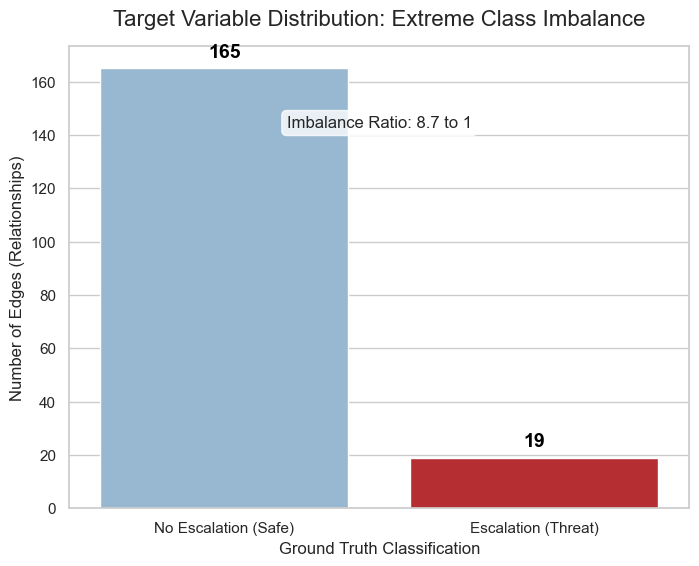

In [9]:
import seaborn as sns
import numpy as np

y_true = enriched_data_sna.y.cpu().numpy()

unique, counts = np.unique(y_true, return_counts=True)
class_counts = dict(zip(unique, counts))

safe_count = class_counts.get(0, 0)
threat_count = class_counts.get(1, 0)

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x=['No Escalation (Safe)', 'Escalation (Threat)'], 
    y=[safe_count, threat_count], 
    palette=['#8ebad9', '#cb181d'] 
)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=14, fontweight='bold', color='black', 
                xytext=(0, 5), textcoords='offset points')

plt.title('Target Variable Distribution: Extreme Class Imbalance', fontsize=16, pad=15)
plt.ylabel('Number of Edges (Relationships)', fontsize=12)
plt.xlabel('Ground Truth Classification', fontsize=12)

imbalance_ratio = safe_count / threat_count if threat_count > 0 else 0
textstr = f'Imbalance Ratio: {imbalance_ratio:.1f} to 1'
plt.text(0.5, 0.85, textstr, transform=ax.transAxes, fontsize=12,
         verticalalignment='top', horizontalalignment='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))


timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_class_distribution.png", dpi=300, bbox_inches='tight')

plt.show()

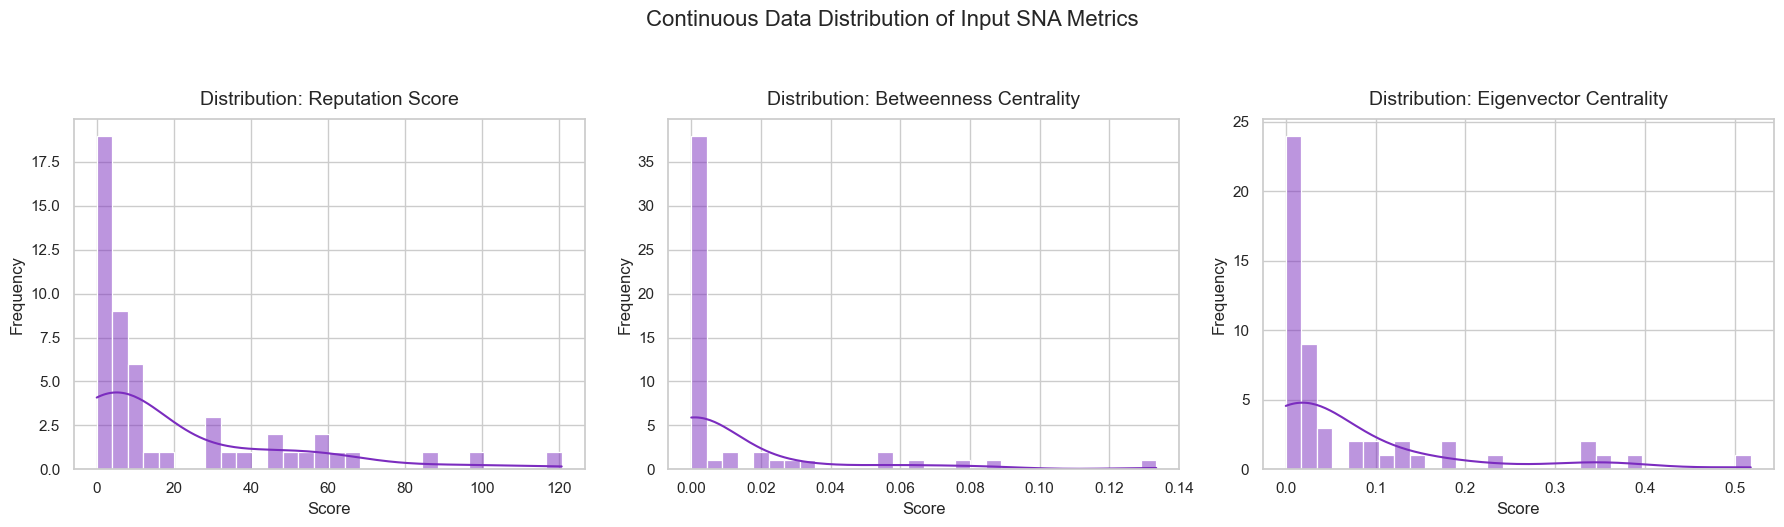

In [10]:
# 1. Extract the raw node features from your PyTorch object
# (We move it to CPU and convert to a numpy array)
node_features = enriched_data_sna.x.cpu().numpy()

# 2. Determine how many features you have
num_features = node_features.shape[1]

# 3. Set up a grid of plots side-by-side
fig, axes = plt.subplots(1, num_features, figsize=(6 * num_features, 5))

# Handle the case where there is only one feature (axes isn't an array)
if num_features == 1:
    axes = [axes]

# 4. Loop through each feature and plot its smooth distribution
# Create a list of the actual metric names
feature_names = ['Reputation Score', 'Betweenness Centrality', 'Eigenvector Centrality']

for i in range(num_features):
    sns.histplot(node_features[:, i], kde=True, ax=axes[i], color='#7b2cbf', bins=30)
    
    # Use the real names from the list!
    actual_name = feature_names[i] if i < len(feature_names) else f'Feature {i}'
    
    axes[i].set_title(f'Distribution: {actual_name}', fontsize=14, pad=10)
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel('Score')

plt.suptitle('Continuous Data Distribution of Input SNA Metrics', fontsize=16, y=1.05)
plt.tight_layout()

# Save for your thesis
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp}_feature_distributions.png", dpi=300, bbox_inches='tight')

plt.show()

## Phase 3: Initialize and train models

In [11]:
from sklearn.preprocessing import StandardScaler
import torch

# Initialize
baseline_model = RiskEscalationGNN(num_node_features=1, hidden_channels=16)
enriched_model = RiskEscalationGNN(num_node_features=3, hidden_channels=16)

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. Scale the Enriched Data features (X)
# We convert to numpy for sklearn, scale it, and convert back to a PyTorch tensor
scaled_features = scaler.fit_transform(enriched_data_sna.x.numpy())
enriched_data_sna.x = torch.tensor(scaled_features, dtype=torch.float)

# We must train on the balanced data so the loss curve matches your K-Fold reality
balanced_baseline_sna = graph_edge_oversample(baseline_data_sna)
balanced_enriched_sna = graph_edge_oversample(enriched_data_sna)

# 3. Train ONLY the models you intend to plot
print("--- Training Baseline Model with SNA ---")
trained_baseline_sna, loss_history_base_sna = train_model(baseline_model, balanced_baseline_sna, epochs=150)

print("\n--- Training Enriched Model with SNA ---")
trained_enriched_sna, loss_history_enriched_sna = train_model(enriched_model, balanced_enriched_sna, epochs=150)


--- Training Baseline Model with SNA ---
Epoch 000 | Loss: 0.6973
Epoch 020 | Loss: 0.6884
Epoch 040 | Loss: 0.6963
Epoch 060 | Loss: 0.6894
Epoch 080 | Loss: 0.6867
Epoch 100 | Loss: 0.6972
Epoch 120 | Loss: 0.6904
Epoch 140 | Loss: 0.6922

--- Training Enriched Model with SNA ---
Epoch 000 | Loss: 0.7106
Epoch 020 | Loss: 0.6502
Epoch 040 | Loss: 0.6303
Epoch 060 | Loss: 0.6337
Epoch 080 | Loss: 0.6007
Epoch 100 | Loss: 0.5256
Epoch 120 | Loss: 0.5721
Epoch 140 | Loss: 0.5365


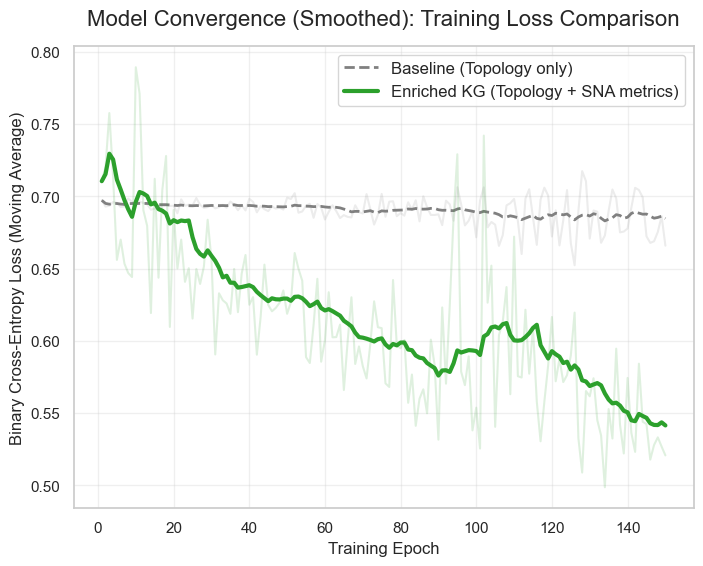

In [12]:
import pandas as pd

# 1. Apply a Rolling Average to smooth the noise (Standard Practice)
window_size = 15 # Averages the loss over 15 epochs

# Convert lists to Pandas Series to easily apply the rolling math
smooth_base = pd.Series(loss_history_base_sna).rolling(window=window_size, min_periods=1).mean()
smooth_enriched = pd.Series(loss_history_enriched_sna).rolling(window=window_size, min_periods=1).mean()

# 2. Set up the academic aesthetic
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
epochs_range = range(1, len(loss_history_enriched_sna) + 1)

# 3. Plot the SMOOTHED learning curves
plt.plot(epochs_range, smooth_base, color='gray', linestyle='--', linewidth=2, label='Baseline (Topology only)')
plt.plot(epochs_range, smooth_enriched, color='#2ca02c', linewidth=3, label='Enriched KG (Topology + SNA metrics)')

# Optional: Plot the raw, noisy data lightly in the background for total transparency
plt.plot(epochs_range, loss_history_enriched_sna, color='#2ca02c', alpha=0.15)
plt.plot(epochs_range, loss_history_base_sna, color='gray', alpha=0.15)

# 4. Add formatting and labels
plt.title('Model Convergence (Smoothed): Training Loss Comparison', fontsize=16, pad=15)
plt.xlabel('Training Epoch', fontsize=12)
plt.ylabel('Binary Cross-Entropy Loss (Moving Average)', fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend(loc='upper right', fontsize=12)

# 5. Save and display
timestamp_conv = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_conv}_convergence_loss_smoothed.png", dpi=300, bbox_inches='tight')

plt.show()

## Phase 4: ROC & Precision-Recall

In [13]:
from sklearn.preprocessing import StandardScaler
import torch

def scale_node_features(data_obj):
    """
    Safely scales node features. Ignores the baseline [1.0] arrays, 
    but standardizes any SNA metrics (Reputation, Betweenness, etc.)
    so the neural network gradients don't explode.
    """
    # Only scale if the dataset has actual features (more than 1 column)
    if data_obj.x.shape[1] > 1:
        scaler = StandardScaler()
        scaled_x = scaler.fit_transform(data_obj.x.cpu().numpy())
        data_obj.x = torch.tensor(scaled_x, dtype=torch.float)
    return data_obj

# 1. Scale all the datasets to ensure the GNN can digest them
baseline_data = scale_node_features(baseline_data)
enriched_data = scale_node_features(enriched_data)
baseline_data_sna = scale_node_features(baseline_data_sna)
enriched_data_sna = scale_node_features(enriched_data_sna)

In [14]:
print("\n" + "="*40)
print("RUNNING K-FOLD ABLATION STUDY...")
print("="*40)

print("1/4: Evaluating Baseline Topology Only...")
y_true_b, preds_b = evaluate_with_kfold(baseline_model, baseline_data, epochs=150)

print("2/4: Evaluating Semantic Edges Only...")
y_true_e, preds_e = evaluate_with_kfold(enriched_model, enriched_data, epochs=150)

print("3/4: Evaluating Baseline + Global SNA...")
y_true_b_sna, preds_b_sna = evaluate_with_kfold(baseline_model, baseline_data_sna, epochs=150)

print("4/4: Evaluating Enriched KG + Global SNA...")
y_true_e_sna, preds_e_sna = evaluate_with_kfold(enriched_model, enriched_data_sna, epochs=150)
print("K-Fold Evaluation Complete!")


RUNNING K-FOLD ABLATION STUDY...
1/4: Evaluating Baseline Topology Only...
Epoch 000 | Loss: 0.6970
Epoch 020 | Loss: 0.6967
Epoch 040 | Loss: 0.6869
Epoch 060 | Loss: 0.6765
Epoch 080 | Loss: 0.6885
Epoch 100 | Loss: 0.6983
Epoch 120 | Loss: 0.6904
Epoch 140 | Loss: 0.6865
Epoch 000 | Loss: 0.6950
Epoch 020 | Loss: 0.6873
Epoch 040 | Loss: 0.6940
Epoch 060 | Loss: 0.6965
Epoch 080 | Loss: 0.6984
Epoch 100 | Loss: 0.6789
Epoch 120 | Loss: 0.7482
Epoch 140 | Loss: 0.6935
Epoch 000 | Loss: 0.7125
Epoch 020 | Loss: 0.6918
Epoch 040 | Loss: 0.6896
Epoch 060 | Loss: 0.6874
Epoch 080 | Loss: 0.6948
Epoch 100 | Loss: 0.6912
Epoch 120 | Loss: 0.6898
Epoch 140 | Loss: 0.6873
Epoch 000 | Loss: 0.6962
Epoch 020 | Loss: 0.7000
Epoch 040 | Loss: 0.6814
Epoch 060 | Loss: 0.6813
Epoch 080 | Loss: 0.6613
Epoch 100 | Loss: 0.7109
Epoch 120 | Loss: 0.6629
Epoch 140 | Loss: 0.7133
Epoch 000 | Loss: 0.6825
Epoch 020 | Loss: 0.7119
Epoch 040 | Loss: 0.6792
Epoch 060 | Loss: 0.6898
Epoch 080 | Loss: 0.6986


OPTIMAL ALARM THRESHOLD DISCOVERED
The mathematically optimal threshold is: 0.446
Maximum F1-Score:    0.218
Resulting Precision: 0.139
Resulting Recall:    0.505


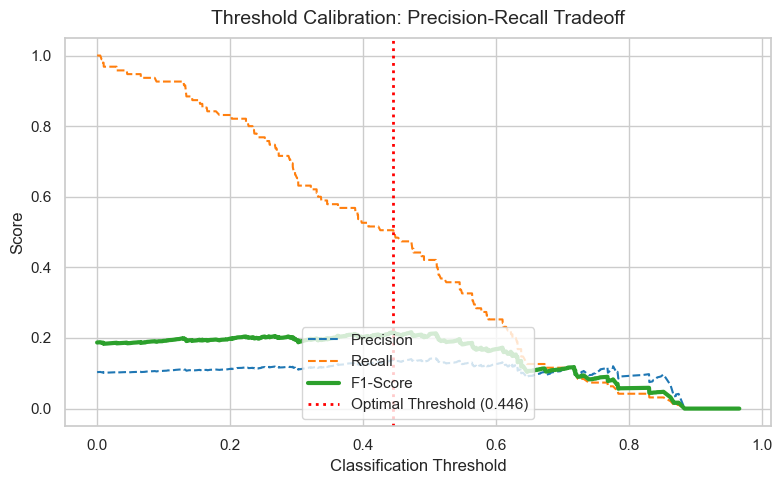

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve

# 1. Flatten the lists of arrays from your K-Fold evaluation
flat_y_true = np.concatenate(y_true_e_sna)
flat_preds = np.concatenate(preds_e_sna)

# 2. Use Scikit-Learn to calculate the exact Precision and Recall for every possible threshold
precision, recall, thresholds = precision_recall_curve(flat_y_true, flat_preds)

# 3. Calculate the F1-Score for every single threshold simultaneously (Vectorized Math)
# Add a tiny epsilon (1e-8) to the denominator to prevent division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

# 4. Find the exact index of the highest F1-Score
# Note: precision_recall_curve returns thresholds with length (N-1), 
# so we drop the last precision/recall value to match shapes
best_index = np.argmax(f1_scores[:-1]) 
optimal_threshold = thresholds[best_index]

print("\n" + "="*40)
print("OPTIMAL ALARM THRESHOLD DISCOVERED")
print("="*40)
print(f"The mathematically optimal threshold is: {optimal_threshold:.3f}")
print(f"Maximum F1-Score:    {f1_scores[best_index]:.3f}")
print(f"Resulting Precision: {precision[best_index]:.3f}")
print(f"Resulting Recall:    {recall[best_index]:.3f}")

# ==========================================
# THESIS UPGRADE: Plotting the Vectorized Threshold Tradeoff
# ==========================================
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# We use thresholds for the x-axis, and slice the other arrays to match the length
plt.plot(thresholds, precision[:-1], label='Precision', color='#1f77b4', linestyle='--')
plt.plot(thresholds, recall[:-1], label='Recall', color='#ff7f0e', linestyle='--')
plt.plot(thresholds, f1_scores[:-1], label='F1-Score', color='#2ca02c', linewidth=3)

# Draw a vertical line at the optimal threshold
plt.axvline(x=optimal_threshold, color='red', linestyle=':', linewidth=2, 
            label=f'Optimal Threshold ({optimal_threshold:.3f})')

plt.title('Threshold Calibration: Precision-Recall Tradeoff', fontsize=14, pad=10)
plt.xlabel('Classification Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.legend(loc='lower center', fontsize=11)
plt.savefig(f"{timestamp}_threshold_calibration.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()


K-FOLD RECALL SCORE (Threshold = 0.45)
Recall: 0.505



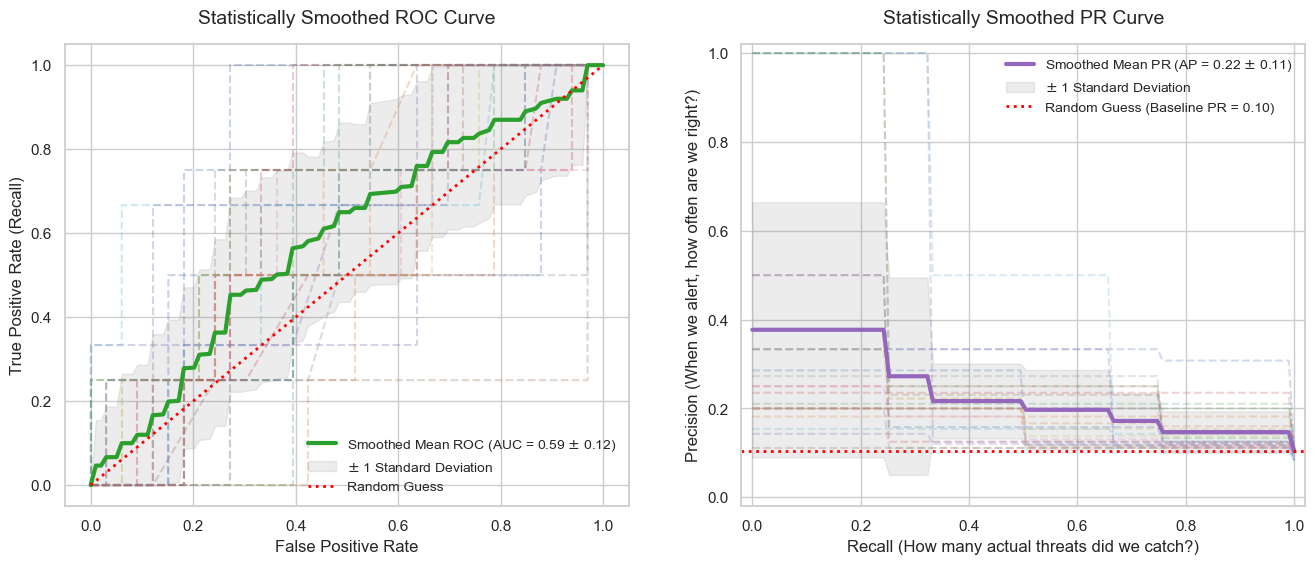

In [16]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, recall_score

flat_y_true = np.concatenate(y_true_e_sna)
flat_preds = np.concatenate(preds_e_sna)

# 2. Apply your optimized threshold to the flattened probabilities
threshold = optimal_threshold
binary_preds = (flat_preds >= threshold).astype(int)

# 3. Calculate the honest scores
honest_recall = recall_score(flat_y_true, binary_preds)

print("\n" + "="*40)
print(f"K-FOLD RECALL SCORE (Threshold = {threshold:.2f})")
print(f"Recall: {honest_recall:.3f}")
print("="*40 + "\n")

# Grab your K-Fold outputs
y_true_folds = y_true_e_sna
y_prob_folds = preds_e_sna

# Set up the side-by-side canvas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# ==========================================
# GRAPH 1: SMOOTHED MEAN ROC (Left Side)
# ==========================================
tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100) 

for i in range(len(y_true_folds)):
    fpr, tpr, _ = roc_curve(y_true_folds[i], y_prob_folds[i])
    roc_auc = auc(fpr, tpr)
    
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    aucs.append(roc_auc)
    
    #ax1.plot(fpr, tpr, alpha=0.3, lw=1.5, linestyle='--', label=f'Fold {i+1} Raw (AUC = {roc_auc:.2f})')
    ax1.plot(fpr, tpr, alpha=0.3, lw=1.5, linestyle='--') # Removed the label!

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

ax1.plot(mean_fpr, mean_tpr, color='#2ca02c', linewidth=3,
        label=r'Smoothed Mean ROC (AUC = %0.2f $\pm$ %0.2f)' % (mean_auc, std_auc))

std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax1.fill_between(mean_fpr, tprs_lower, tprs_upper, color='grey', alpha=0.15,
                label=r'$\pm$ 1 Standard Deviation')

ax1.plot([0, 1], [0, 1], linestyle=':', lw=2, color='red', label='Random Guess')
ax1.set_title('Statistically Smoothed ROC Curve', fontsize=14, pad=15)
ax1.set_xlabel('False Positive Rate', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend(loc="lower right", fontsize=10, framealpha=0.9)


# ==========================================
# GRAPH 2: STATISTICALLY SMOOTHED PR CURVE (Right Side)
# ==========================================
precisions = []
aps = []
mean_recall = np.linspace(0, 1, 100) 

for i in range(len(y_true_folds)):
    precision, recall, _ = precision_recall_curve(y_true_folds[i], y_prob_folds[i])
    fold_ap = average_precision_score(y_true_folds[i], y_prob_folds[i])
    aps.append(fold_ap)
    
    # ---> THE SMOOTHING FIX: Enforce Monotonicity (Max-Precision to the right) <---
    # Since Scikit-Learn outputs recall in descending order, a cumulative max
    # from the front eliminates all the jagged downward drops.
    precision_smoothed = np.maximum.accumulate(precision)
    
    # Interpolate using the smoothed monotonic values
    interp_precision = np.interp(mean_recall, recall[::-1], precision_smoothed[::-1])
    precisions.append(interp_precision)
    
    # Plot the raw folds with the same smoothing so the background matches
    #ax2.plot(mean_recall, interp_precision, alpha=0.25, lw=1.5, linestyle='--', label=f'Fold {i+1} (AP = {fold_ap:.2f})')
    ax2.plot(mean_recall, interp_precision, alpha=0.25, lw=1.5, linestyle='--')

# Calculate the statistical average (Mean) of the 3 smoothed folds
mean_precision = np.mean(precisions, axis=0)
mean_ap = np.mean(aps)
std_ap = np.std(aps)

# Plot the final beautifully SMOOTHED Mean PR line
ax2.plot(mean_recall, mean_precision, color='#9467bd', linewidth=3,
        label=r'Smoothed Mean PR (AP = %0.2f $\pm$ %0.2f)' % (mean_ap, std_ap))

# Add the grey standard deviation shading
std_precision = np.std(precisions, axis=0)
precisions_upper = np.minimum(mean_precision + std_precision, 1)
precisions_lower = np.maximum(mean_precision - std_precision, 0)
ax2.fill_between(mean_recall, precisions_lower, precisions_upper, color='grey', alpha=0.15,
                label=r'$\pm$ 1 Standard Deviation')

# Format the Baseline
y_true_flat = np.concatenate(y_true_folds)
baseline_pr = sum(y_true_flat) / len(y_true_flat)
ax2.axhline(y=baseline_pr, color='red', linestyle=':', lw=2, 
            label=f'Random Guess (Baseline PR = {baseline_pr:.2f})')

# Format the Graph
ax2.set_title('Statistically Smoothed PR Curve', fontsize=14, pad=15)
ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=12)
ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=12)
ax2.set_xlim([-0.02, 1.02]) # Clean up edges
ax2.set_ylim([-0.02, 1.02])
ax2.legend(loc='upper right', fontsize=10, framealpha=0.9)

# Save and Show
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp}_final_smoothed_evaluation_dual.png", dpi=300, bbox_inches='tight')
plt.show()

## Final reports

In [22]:
#import pandas as pd
#from IPython.display import display
#from datetime import datetime
# Assuming generate_threat_report is imported correctly

threat_alerts = generate_threat_report(trained_enriched_sna, enriched_data_sna, reverse_mapping, threshold=0.7)

# FIX 3: Safety check to prevent KeyError on empty DataFrames
if not threat_alerts:
    print(f"✅ No threats detected above the {optimal_threshold*100}% threshold. The yard is safe.")
else:
    # 1. Convert to DataFrame and keep only the columns we need
    df_alerts = pd.DataFrame(threat_alerts)[['source', 'target', 'probability']]

    # 2. Rename columns for the professional output
    df_alerts.columns = ['Source Node', 'Target Node', 'Risk Score']

    # 3. Apply the gradient AND the percentage formatting in one smooth chain!
    styled_table = df_alerts.style.background_gradient(
        subset=['Risk Score'], cmap='Reds', vmin=50.0, vmax=100.0
    ).format(
        {'Risk Score': "{:.1f}%"}
    ).set_caption(f"High-Risk Threat Escalation Report (Threshold: {optimal_threshold})")

    # 4. Save straight to HTML (Optional)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    # html_filename = f"threat_table_final_{timestamp}.html"
    # styled_table.to_html(html_filename)
    
    # Display the beautiful table directly in your notebook
styled_table

,Source Node,Target Node,Risk Score
0,Unknown_Assailant,Torres,79.3%
1,Diaz,Violent Retribution,78.6%
2,Diaz,Disrespect,78.6%
3,Diaz,Protective Measures,78.6%
4,Diaz,Rival Inmates,78.5%
5,Attacker,Batista,73.7%
6,O'Reilly,Hispanic Inmate,70.7%
7,O'Reilly,Hispanic Inmate,70.7%


In [23]:
from neo4j import GraphDatabase
from core.config import graph_base

def enrich_alerts_with_predicates(alerts_list):
    print("🔍 Fetching original semantic predicates from Neo4j...")
    driver = GraphDatabase.driver(graph_base.URL, auth=(graph_base.USER, graph_base.PASS))
    
    with driver.session() as session:
        for alert in alerts_list:
            src = alert['source']
            tgt = alert['target']
            
            # Ask Neo4j what the original LLM-extracted relationship was
            # We explicitly ignore the mathematical SNA edges to get the real action
            query = """
            MATCH (a:Inmate {name: $src})-[r]->(b:Inmate {name: $tgt})
            WHERE type(r) <> 'SNA_TIE_STRENGTH'
            RETURN type(r) AS predicate LIMIT 1
            """
            result = session.run(query, src=src, tgt=tgt).single()
            
            # If Neo4j finds the predicate (e.g., 'ASSAULTS'), save it into the dictionary!
            if result and result['predicate']:
                alert['predicate'] = result['predicate']
            
    driver.close()
    print("✅ Enrichment complete!")
    return alerts_list

# Update your existing alerts list with the real words
threat_alerts = enrich_alerts_with_predicates(threat_alerts)

🔍 Fetching original semantic predicates from Neo4j...
✅ Enrichment complete!


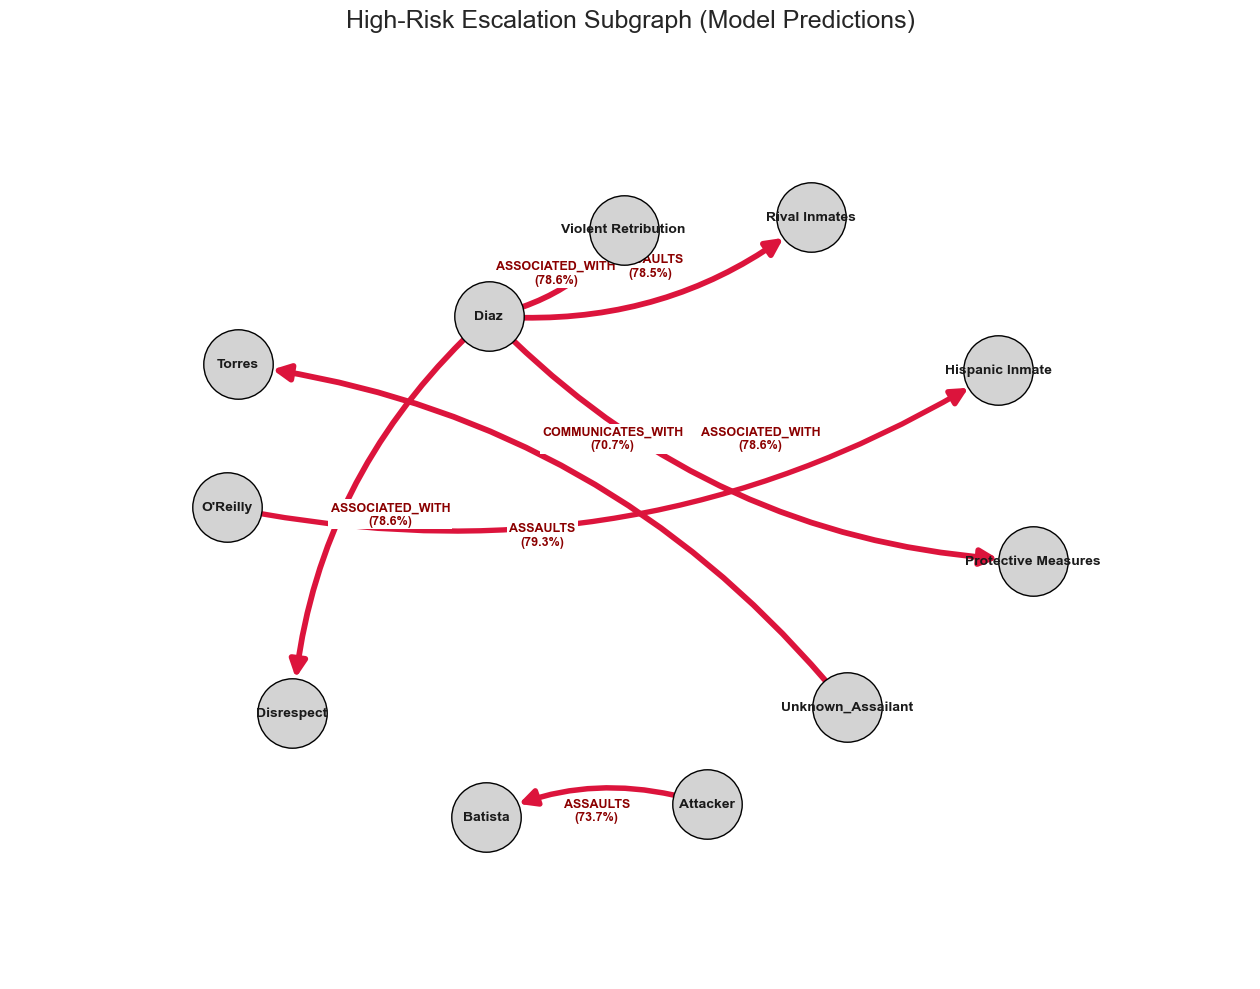

In [25]:
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime

# 1. Create a blank, directed graph
G_threat = nx.DiGraph()

# 2. Add edges safely WITH LABELS
for alert in threat_alerts:
    src = alert['source']
    tgt = alert['target']
    
    prob_pct_string = f"{alert['probability']:.1f}%"
    predicate = alert.get('predicate', 'ESCALATES')
    
    arrow_label = f"{predicate}\n({prob_pct_string})"
    
    prob = float(alert['probability'])
    if prob > 1.0: 
        prob = prob / 100.0 
        
    G_threat.add_edge(src, tgt, weight=prob, label=arrow_label)

# 3. Set up a massive canvas
plt.figure(figsize=(16, 12)) 

# The Spring Layout Rescue
pos = nx.spring_layout(G_threat, k=4.0, iterations=100, seed=15)

# TWEAK 1: Reduced node size for better visual proportion
NODE_SIZE = 2500

# 4. Draw the Nodes
nx.draw_networkx_nodes(G_threat, pos, node_color='lightgrey', 
                       edgecolors='black', node_size=NODE_SIZE, alpha=1.0)

# Draw Node Labels
nx.draw_networkx_labels(G_threat, pos, font_size=10, font_weight='bold')

# 5. Draw the Edges (Arrows)
edge_widths = [1 + (G_threat[u][v]['weight'] * 4) for u, v in G_threat.edges()]

# The Gentle Curve
nx.draw_networkx_edges(G_threat, pos, 
                       arrowstyle='-|>', 
                       arrowsize=25, 
                       edge_color='crimson', 
                       width=edge_widths, 
                       node_size=NODE_SIZE, 
                       connectionstyle="arc3,rad=0.2") 

# 6. Add the Edge Labels
edge_labels = nx.get_edge_attributes(G_threat, 'label')

# TWEAK 2 & 3: rotate=False and pad=1.5
# This forces the text to be horizontal and carves a larger white space over the red arrows
nx.draw_networkx_edge_labels(G_threat, pos, edge_labels=edge_labels, 
                             font_color='darkred', font_size=9, font_weight='bold',
                             rotate=False, 
                             bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, pad=1.5))

# 7. Formatting
plt.title("High-Risk Escalation Subgraph (Model Predictions)", fontsize=18, pad=20)
plt.margins(0.2) 
plt.axis('off')

# Save and show
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp}_threat_subgraph_final.png", dpi=300, bbox_inches='tight')

plt.show()